# Model v2 and model v3 on the same test period

The two models of the SMARD phases of the [roadmap](../ROADMAP.md) on the same 573 days, 1 April 2025 to 28 October 2026, with the figures of [`03_results.ipynb`](03_results.ipynb):

- **Model v2** (phase 2): LightGBM, the mean of three seeds, with the prices of D-1 in Germany and the coupled neighbouring markets and the day-ahead forecasts for Germany and Austria; **trained once** on the days until March 2025 and used unchanged for the whole test period. Its forecasts are computed here from the saved models in `models/final_v2/`, exactly as in its test (`reports/test_results_v2.md`).
- **Model v3** (phase 3): the mean of LightGBM and an LSTM, three seeds each, with the **gas and CO2 prices** in addition, **refitted at the start of every month** on all days before it. Its forecasts are those of its test in `reports/forecasts_v3_test.csv` (`reports/test_results_v3.md`).

Both use only what is known at 12:00 on D-1, and every forecast comes from a model that had not seen the day. The difference between them combines three changes, the fuel prices, the LSTM in the combination and the monthly refits; the roadmap decided them one by one on the validation year. All errors are in EUR/MWh; a positive error means the forecast was too high.

In [ ]:
import contextlib
import io

import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from spotforecast.config import PROJECT_ROOT, load_config, load_data_config
from spotforecast.data.dataset import load_datasets
from spotforecast.final_v2 import FINAL_DIR as V2_DIR
from spotforecast.models.baselines import lgbm_table, stack_windows
from spotforecast.predict import CONTEXT_COLOR, MUTED_COLOR, TEXT_COLOR, style_axes

plt.rcParams.update({"figure.facecolor": "white", "savefig.facecolor": "white", "figure.dpi": 110})
# slots 1 and 2 of the validated categorical palette; the baseline day D-1 is gray context
COLORS = {"v2": "#eb6834", "v3": "#2a78d6"}
LABELS = {"naive": "day D-1", "v2": "model v2", "v3": "model v3"}
MAIN = ["v2", "v3"]
label = lambda name: LABELS.get(name, name)
color = lambda name: COLORS.get(name, CONTEXT_COLOR)


def date_axis(ax):
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))


# model v2: the forecasts of its three saved LightGBM models on the test split of its data
config = load_config("lgbm_v2")
with contextlib.redirect_stdout(io.StringIO()):  # the preprocessing log is long
    _, _, test_ds = load_datasets(config, load_data_config(config))
X, Y = stack_windows(test_ds)
table = lgbm_table(X, Y)[0]
scaled = np.mean([lgb.Booster(model_file=str(V2_DIR / f"final_{config['model_name']}_seed{seed}.txt")).predict(table)
                  for seed in config["seeds"]], axis=0).reshape(len(X), -1)
v2 = scaled * test_ds.target_scaler.scale_[0] + test_ds.target_scaler.mean_[0]
v2_days = test_ds.forecast_starts().strftime("%Y-%m-%d")
v2_hourly = pd.DataFrame({"day": np.repeat(v2_days, 24), "hour": np.tile(np.arange(24), len(v2_days)),
                          "v2": v2.ravel()})

# model v3 and the baseline day D-1 from the test of model v3, joined on the same days and hours
v3_hourly = pd.read_csv(PROJECT_ROOT / "reports" / "forecasts_v3_test.csv")
hourly = v3_hourly[["day", "hour", "actual", "naive", "v3"]].merge(v2_hourly, on=["day", "hour"], how="inner",
                                                                   validate="one_to_one")
hourly = hourly.sort_values(["day", "hour"], ignore_index=True)
assert len(hourly) == len(v2_hourly) == len(v3_hourly), "both models must forecast the same hours"

days = pd.DatetimeIndex(sorted(hourly["day"].unique()))
pivot = lambda column: hourly.pivot(index="day", columns="hour", values=column).to_numpy()
actual = pivot("actual")
forecasts = {name: pivot(name) for name in ["naive", "v2", "v3"]}
errors = {name: pred - actual for name, pred in forecasts.items()}
daily_mae = {name: np.abs(err).mean(axis=1) for name, err in errors.items()}
hours = pd.DatetimeIndex(pd.to_datetime(hourly["day"]) + pd.to_timedelta(hourly["hour"], unit="h"))

# the hourly prices of the SMARD data, for the two days before a forecast day in section 8
smard = pd.read_parquet(PROJECT_ROOT / "data" / "raw" / "smard.parquet", columns=["Date", "Spot"])
spot = pd.Series(smard["Spot"].to_numpy(), index=smard["Date"].dt.tz_localize(None))

print(f"test period: {days[0]:%d %b %Y} to {days[-1]:%d %b %Y}, {len(days)} days, {actual.size} hours; "
      f"price {actual.min():.0f} to {actual.max():.0f}, mean {actual.mean():.1f} EUR/MWh")
print(f"MAE of model v2 recomputed from models/final_v2: {np.abs(errors['v2']).mean():.2f} (its test report: 16.9)")

test period: 01 Apr 2025 to 28 Oct 2026, 573 days, 13752 hours; price -499 to 697, mean 98.2 EUR/MWh
MAE of model v2 recomputed from models/final_v2: 16.89 (its test report: 16.9)


## 1. Overview

Both models on the test period. **Bias** is the mean of the signed errors (negative: too low on average), **within 10 / 20** the share of hours with an error below 10 and 20 EUR/MWh. The MAE values are those of `reports/test_results_v2.md` and `reports/test_results_v3.md`.

In [ ]:
summary = pd.DataFrame({label(name): {
    "MAE": np.abs(errors[name]).mean(),
    "RMSE": np.sqrt((errors[name] ** 2).mean()),
    "bias": errors[name].mean(),
    "median abs. error": np.median(np.abs(errors[name])),
    "max abs. error": np.abs(errors[name]).max(),
    "within 10": (np.abs(errors[name]) < 10).mean(),
    "within 20": (np.abs(errors[name]) < 20).mean(),
} for name in ["naive", "v2", "v3"]}).T
display(summary.style.format("{:.1f}").format("{:.0%}", subset=["within 10", "within 20"]))

,MAE,RMSE,bias,median abs. error,max abs. error,within 10,within 20
day D-1,29.0,45.4,-0.3,16.4,467.3,35%,56%
model v2,16.9,27.3,-7.5,10.5,384.6,48%,73%
model v3,13.5,23.3,-2.4,8.9,398.4,55%,80%


## 2. The whole test period

The daily mean of the actual price and of both forecasts over the 19 months (every hour, as in notebook 03, would be too dense here). The second figure zooms into the two weeks around the highest price of the test period, every hour.

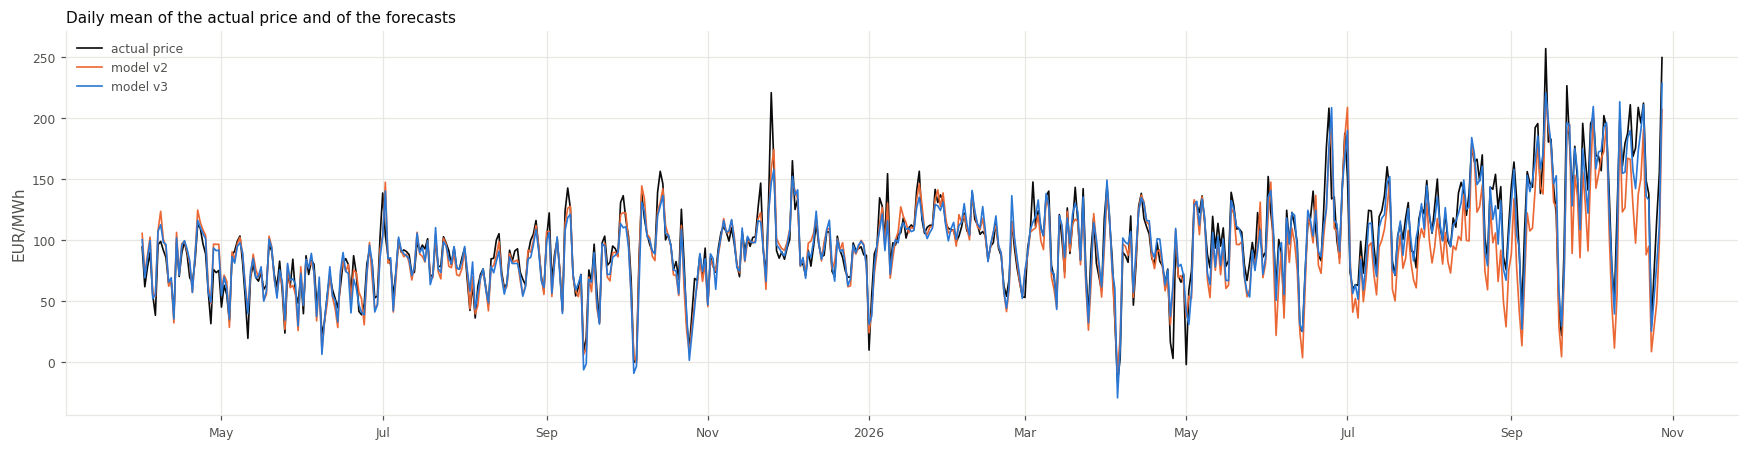

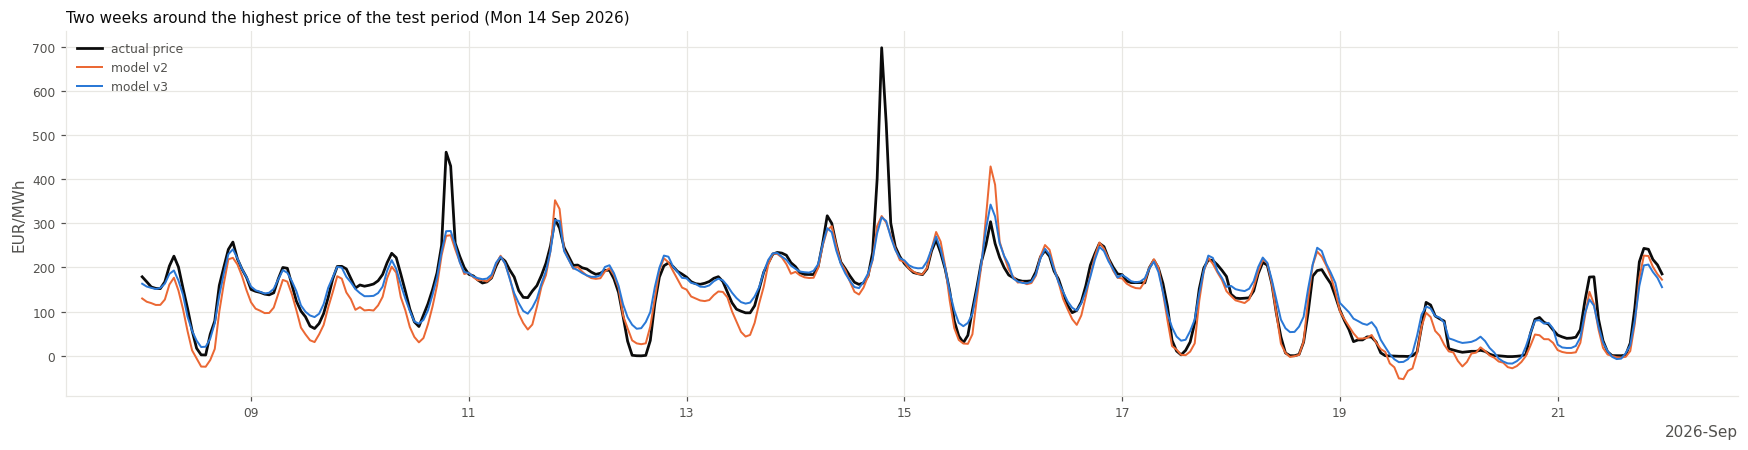

In [1]:
fig, ax = plt.subplots(figsize=(16, 4.2))
ax.plot(days, actual.mean(axis=1), color=TEXT_COLOR, linewidth=1.1, label="actual price")
for name in MAIN:
    ax.plot(days, forecasts[name].mean(axis=1), color=color(name), linewidth=1.1, label=label(name))
style_axes(ax, "Daily mean of the actual price and of the forecasts")
ax.set_ylabel("EUR/MWh")
date_axis(ax)
ax.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper left")
plt.tight_layout()
plt.show()

peak_day = days[np.argmax(actual.max(axis=1))]
zoom = (hours >= peak_day - pd.Timedelta(days=6)) & (hours < peak_day + pd.Timedelta(days=8))
fig, ax = plt.subplots(figsize=(16, 4.2))
ax.plot(hours[zoom], actual.ravel()[zoom], color=TEXT_COLOR, linewidth=1.8, label="actual price")
for name in MAIN:
    ax.plot(hours[zoom], forecasts[name].ravel()[zoom], color=color(name), linewidth=1.3, label=label(name))
style_axes(ax, f"Two weeks around the highest price of the test period ({peak_day:%a %d %b %Y})")
ax.set_ylabel("EUR/MWh")
date_axis(ax)
ax.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper left")
plt.tight_layout()
plt.show()

## 3. Day by day

Top: the daily mean price and the range from the lowest to the highest hour of the day. Bottom: the daily MAE of both models and of the baseline day D-1, as a 7-day rolling mean (573 single days would be too noisy).

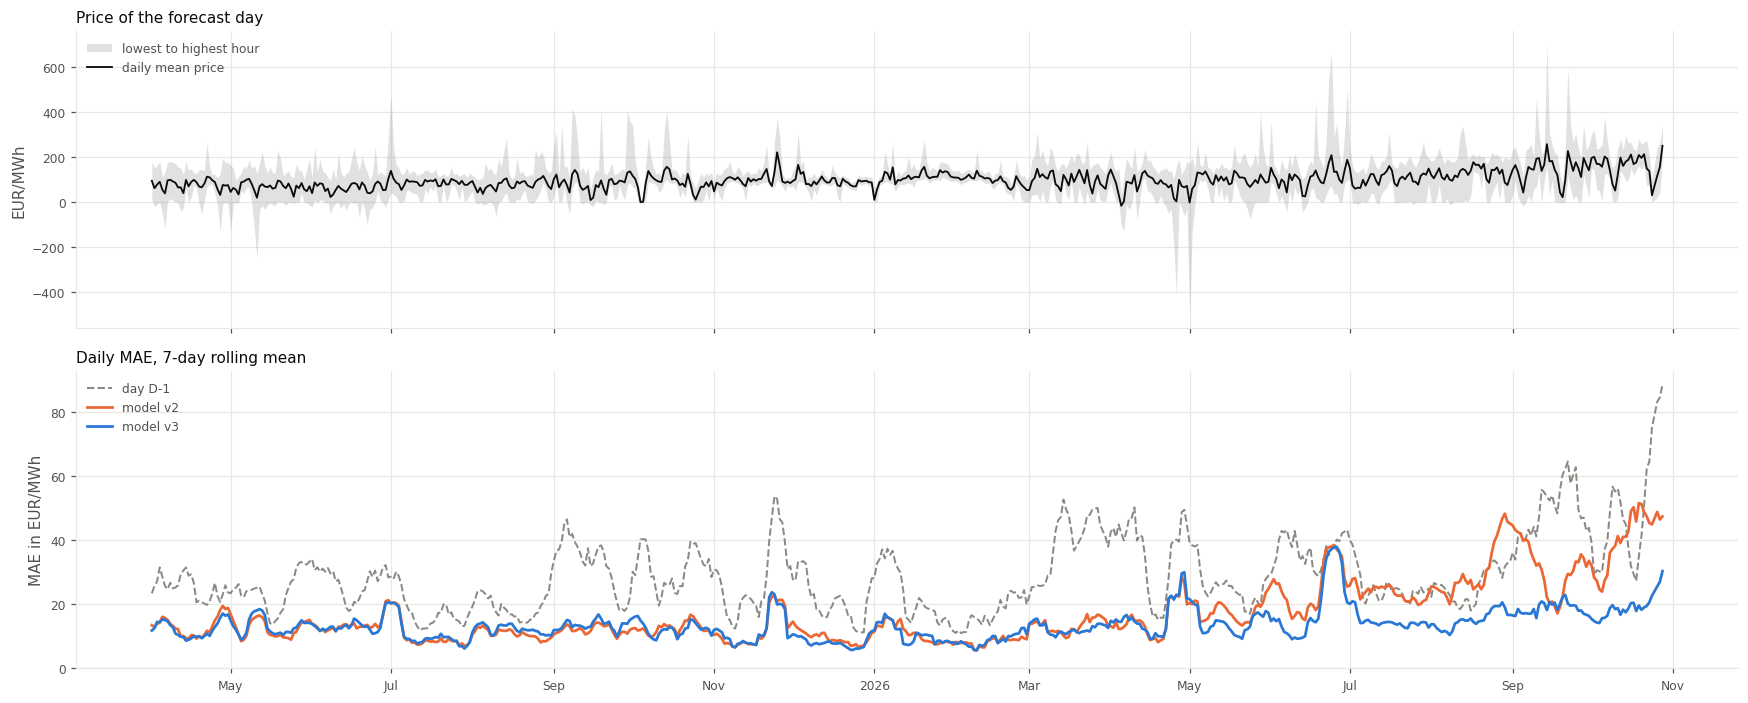

daily MAE of model v2: median 12.8, best day 2.7, worst day 77.9; better than day D-1 on 78% of the days
daily MAE of model v3: median 11.3, best day 2.6, worst day 74.8; better than day D-1 on 85% of the days


In [2]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(16, 6.5), sharex=True)
top.fill_between(days, actual.min(axis=1), actual.max(axis=1), color=CONTEXT_COLOR, alpha=0.25, linewidth=0,
                 label="lowest to highest hour")
top.plot(days, actual.mean(axis=1), color=TEXT_COLOR, linewidth=1.2, label="daily mean price")
style_axes(top, "Price of the forecast day")
top.set_ylabel("EUR/MWh")
top.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper left")

rolling = lambda values: pd.Series(values, index=days).rolling(7, center=True, min_periods=4).mean()
bottom.plot(days, rolling(daily_mae["naive"]), color=CONTEXT_COLOR, linewidth=1.3, linestyle="--",
            label=label("naive"))
for name in MAIN:
    bottom.plot(days, rolling(daily_mae[name]), color=color(name), linewidth=1.8, label=label(name))
style_axes(bottom, "Daily MAE, 7-day rolling mean")
bottom.set_ylabel("MAE in EUR/MWh")
bottom.set_ylim(bottom=0)
bottom.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper left")
date_axis(bottom)
plt.tight_layout()
plt.show()

for name in MAIN:
    print(f"daily MAE of {label(name)}: median {np.median(daily_mae[name]):.1f}, best day {daily_mae[name].min():.1f}, "
          f"worst day {daily_mae[name].max():.1f}; better than day D-1 on "
          f"{(daily_mae[name] < daily_mae['naive']).mean():.0%} of the days")

## 4. Hour of the day

The MAE of every hour of the forecast day.

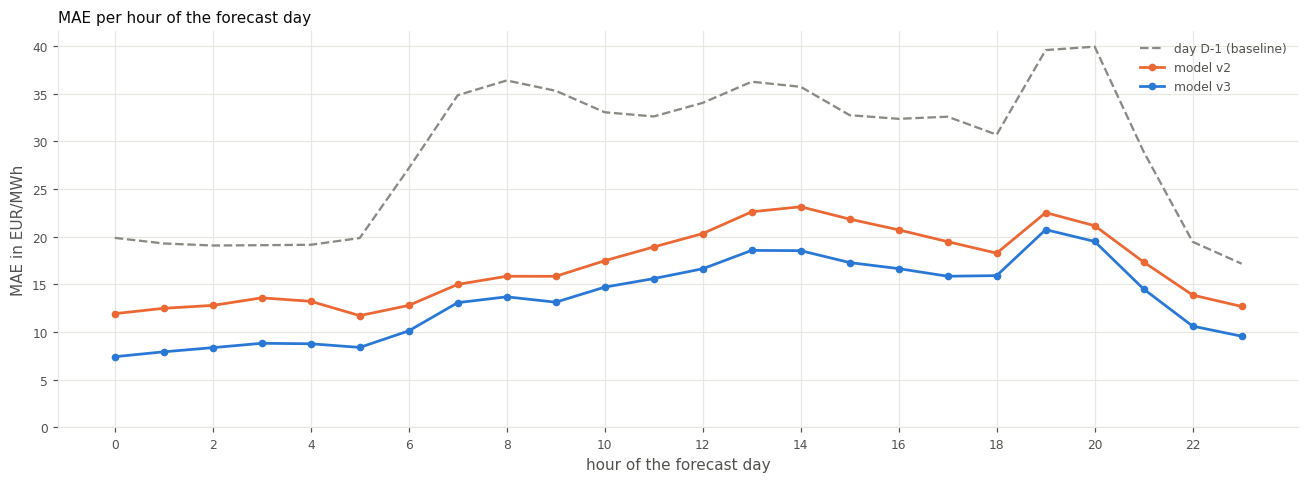

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.5))
hour_of_day = np.arange(24)
ax.plot(hour_of_day, np.abs(errors["naive"]).mean(axis=0), color=CONTEXT_COLOR, linewidth=1.5, linestyle="--",
        label="day D-1 (baseline)")
for name in MAIN:
    ax.plot(hour_of_day, np.abs(errors[name]).mean(axis=0), color=color(name), linewidth=1.8, marker="o",
            markersize=4, label=label(name))
style_axes(ax, "MAE per hour of the forecast day")
ax.set_xlabel("hour of the forecast day")
ax.set_ylabel("MAE in EUR/MWh")
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(bottom=0)
ax.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR)
plt.tight_layout()
plt.show()

## 5. Weekday and price level

Left: the MAE per weekday. Right: the MAE per level of the actual price, with the number of hours in each level.

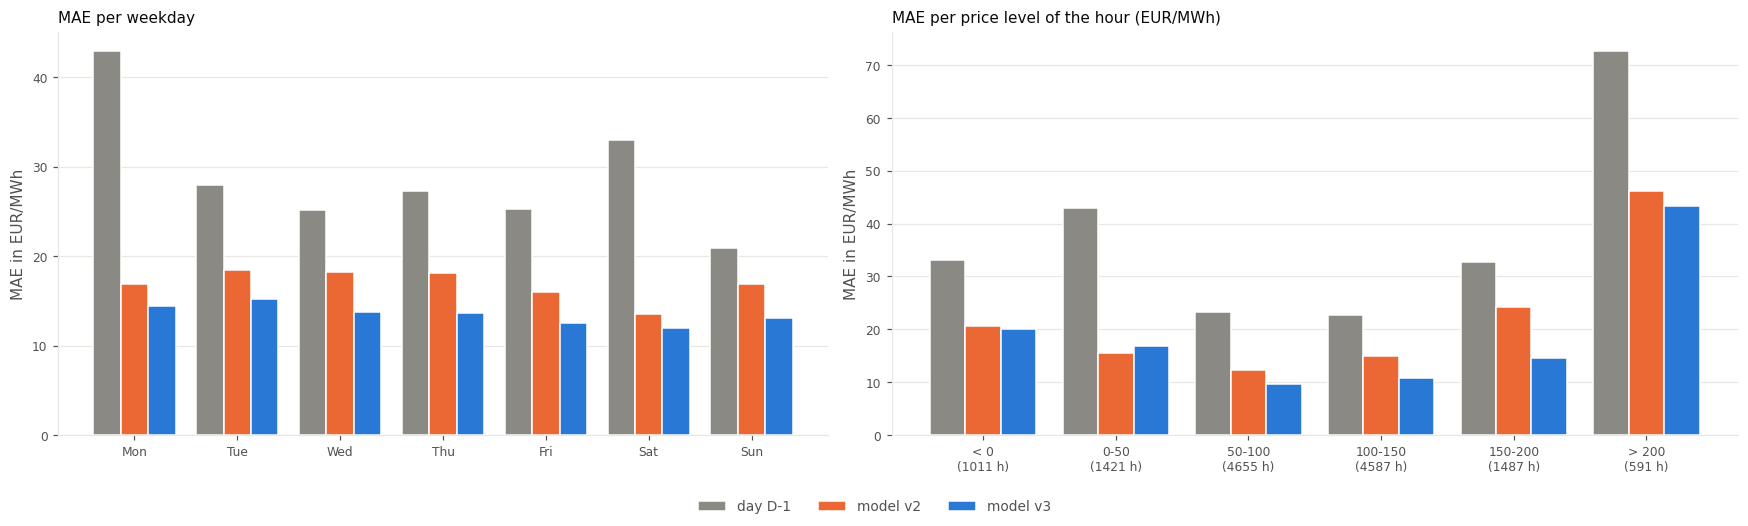

day D-1  model v2  model v3
weekday     Mon                   43.0      16.9      14.4
            Tue                   27.9      18.4      15.2
            Wed                   25.2      18.3      13.7
            Thu                   27.3      18.2      13.6
            Fri                   25.3      16.0      12.5
            Sat                   33.0      13.5      11.9
            Sun                   20.9      16.9      13.0
price level < 0\n(1011 h)         33.1      20.7      20.0
            0-50\n(1421 h)        43.0      15.5      16.9
            50-100\n(4655 h)      23.3      12.4       9.6
            100-150\n(4587 h)     22.6      14.9      10.7
            150-200\n(1487 h)     32.7      24.3      14.7
            > 200\n(591 h)        72.7      46.2      43.2

In [4]:
def grouped_bars(ax, table, title, ylabel):
    width = 0.8 / len(table.columns)
    for k, name in enumerate(table.columns):
        ax.bar(np.arange(len(table)) + (k - (len(table.columns) - 1) / 2) * width, table[name], width=width,
               color=color(name), edgecolor="white", linewidth=1, label=label(name))
    ax.set_xticks(np.arange(len(table)), table.index)
    style_axes(ax, title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)


names = ["naive"] + MAIN
weekday = pd.Series(days.dayofweek, name="weekday")
by_weekday = pd.DataFrame({name: pd.Series(daily_mae[name]).groupby(weekday).mean() for name in names})
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

levels = pd.cut(actual.ravel(), [-np.inf, 0, 50, 100, 150, 200, np.inf],
                labels=["< 0", "0-50", "50-100", "100-150", "150-200", "> 200"])
by_level = pd.DataFrame({name: pd.Series(np.abs(errors[name]).ravel()).groupby(levels, observed=True).mean()
                         for name in names})
counts = pd.Series(levels).value_counts().reindex(by_level.index)
by_level.index = [f"{level}\n({n} h)" for level, n in counts.items()]

fig, (left, right) = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
grouped_bars(left, by_weekday, "MAE per weekday", "MAE in EUR/MWh")
grouped_bars(right, by_level, "MAE per price level of the hour (EUR/MWh)", "MAE in EUR/MWh")
handles, labels = left.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, fontsize=9, labelcolor=MUTED_COLOR)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()
display(pd.concat({"weekday": by_weekday, "price level": by_level}).rename(columns=LABELS).round(1))

## 6. How the errors are distributed

Left: the signed errors of every hour (errors beyond ±150 EUR/MWh are counted at the edge). Middle and right: forecast against actual price of every hour for each model; points below the diagonal are forecasts that were too low.

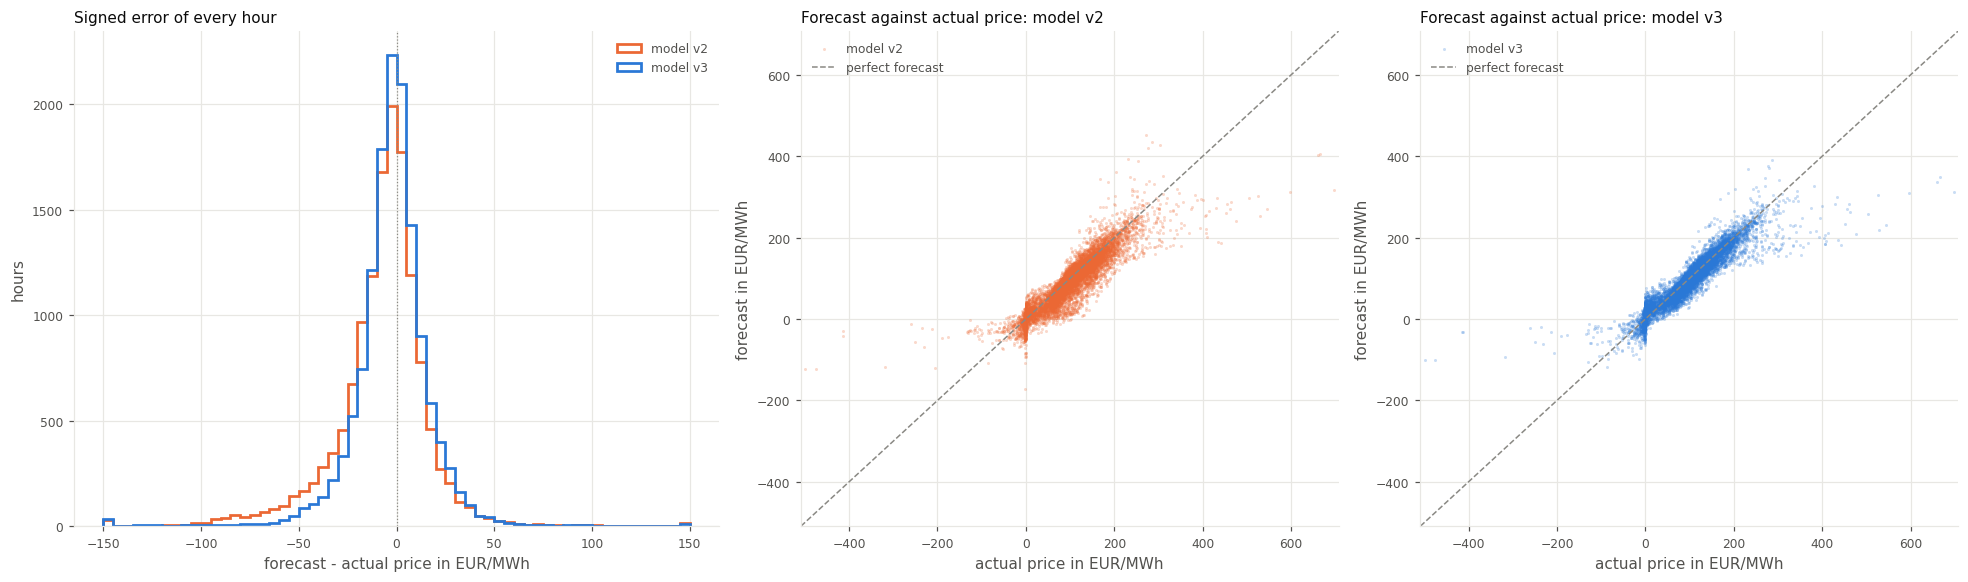

bias of model v2: -7.5 overall, -6.3 at prices up to 200, -33.7 above 200 EUR/MWh (591 hours)
bias of model v3: -2.4 overall, -1.0 at prices up to 200, -34.1 above 200 EUR/MWh (591 hours)


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4), gridspec_kw={"width_ratios": [1.2, 1, 1]})
bins = np.arange(-150, 155, 5)
for name in MAIN:
    axes[0].hist(np.clip(errors[name].ravel(), -150, 150), bins=bins, histtype="step", linewidth=1.8,
                 color=color(name), label=label(name))
axes[0].axvline(0, color=CONTEXT_COLOR, linewidth=0.8, linestyle=":")
style_axes(axes[0], "Signed error of every hour")
axes[0].set_xlabel("forecast - actual price in EUR/MWh")
axes[0].set_ylabel("hours")
axes[0].legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR)

limits = [min(actual.min(), *(forecasts[n].min() for n in MAIN)) - 10, actual.max() + 10]
for ax, name in zip(axes[1:], MAIN):
    ax.scatter(actual.ravel(), forecasts[name].ravel(), s=4, alpha=0.25, color=color(name), linewidths=0,
               label=label(name))
    ax.plot(limits, limits, color=CONTEXT_COLOR, linewidth=1, linestyle="--", label="perfect forecast")
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    style_axes(ax, f"Forecast against actual price: {label(name)}")
    ax.set_xlabel("actual price in EUR/MWh")
    ax.set_ylabel("forecast in EUR/MWh")
    ax.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper left")
plt.tight_layout()
plt.show()

high = actual > 200
for name in MAIN:
    print(f"bias of {label(name)}: {errors[name].mean():+.1f} overall, {errors[name][~high].mean():+.1f} at prices up "
          f"to 200, {errors[name][high].mean():+.1f} above 200 EUR/MWh ({high.sum()} hours)")

## 7. Where model v3 is better

Each point is a test day: the daily MAE of model v3 against that of model v2. Points above the diagonal are days on which model v3 was better. The days from May 2026, when the price rose from about 80 to 163 EUR/MWh, are marked separately.

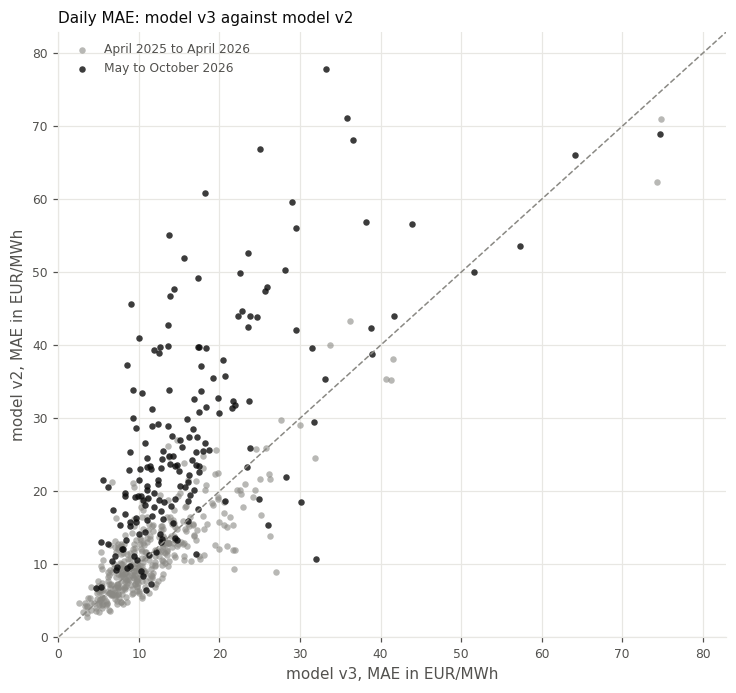

model v3 is better on 327 of 573 days (57%); until April 2026 on 43%, from May 2026 on 88%
MAE until April 2026: v2 11.8, v3 11.9; from May 2026: v2 28.0, v3 17.0
correlation of the hourly errors 0.84


In [6]:
late = days >= "2026-05-01"
fig, ax = plt.subplots(figsize=(6.8, 6.4))
ax.scatter(daily_mae["v3"][~late], daily_mae["v2"][~late], s=18, alpha=0.6, color=CONTEXT_COLOR, linewidths=0,
           label="April 2025 to April 2026")
ax.scatter(daily_mae["v3"][late], daily_mae["v2"][late], s=18, alpha=0.8, color=TEXT_COLOR, linewidths=0,
           label="May to October 2026")
upper = max(daily_mae["v2"].max(), daily_mae["v3"].max()) + 5
ax.plot([0, upper], [0, upper], color=CONTEXT_COLOR, linewidth=1, linestyle="--")
ax.set_xlim(0, upper)
ax.set_ylim(0, upper)
style_axes(ax, "Daily MAE: model v3 against model v2")
ax.set_xlabel(f"{label('v3')}, MAE in EUR/MWh")
ax.set_ylabel(f"{label('v2')}, MAE in EUR/MWh")
ax.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR, loc="upper left")
plt.tight_layout()
plt.show()

v3_better = daily_mae["v3"] < daily_mae["v2"]
print(f"model v3 is better on {v3_better.sum()} of {len(days)} days ({v3_better.mean():.0%}); "
      f"until April 2026 on {v3_better[~late].mean():.0%}, from May 2026 on {v3_better[late].mean():.0%}")
print(f"MAE until April 2026: v2 {daily_mae['v2'][~late].mean():.1f}, v3 {daily_mae['v3'][~late].mean():.1f}; "
      f"from May 2026: v2 {daily_mae['v2'][late].mean():.1f}, v3 {daily_mae['v3'][late].mean():.1f}")
print(f"correlation of the hourly errors {np.corrcoef(errors['v2'].ravel(), errors['v3'].ravel())[0, 1]:.2f}")

## 8. Single days

Six test days: a typical day (median error of model v3), the best and the worst forecast of model v3, the highest and the lowest price, and a typical Sunday. Gray: the known prices of the two days before the forecast.

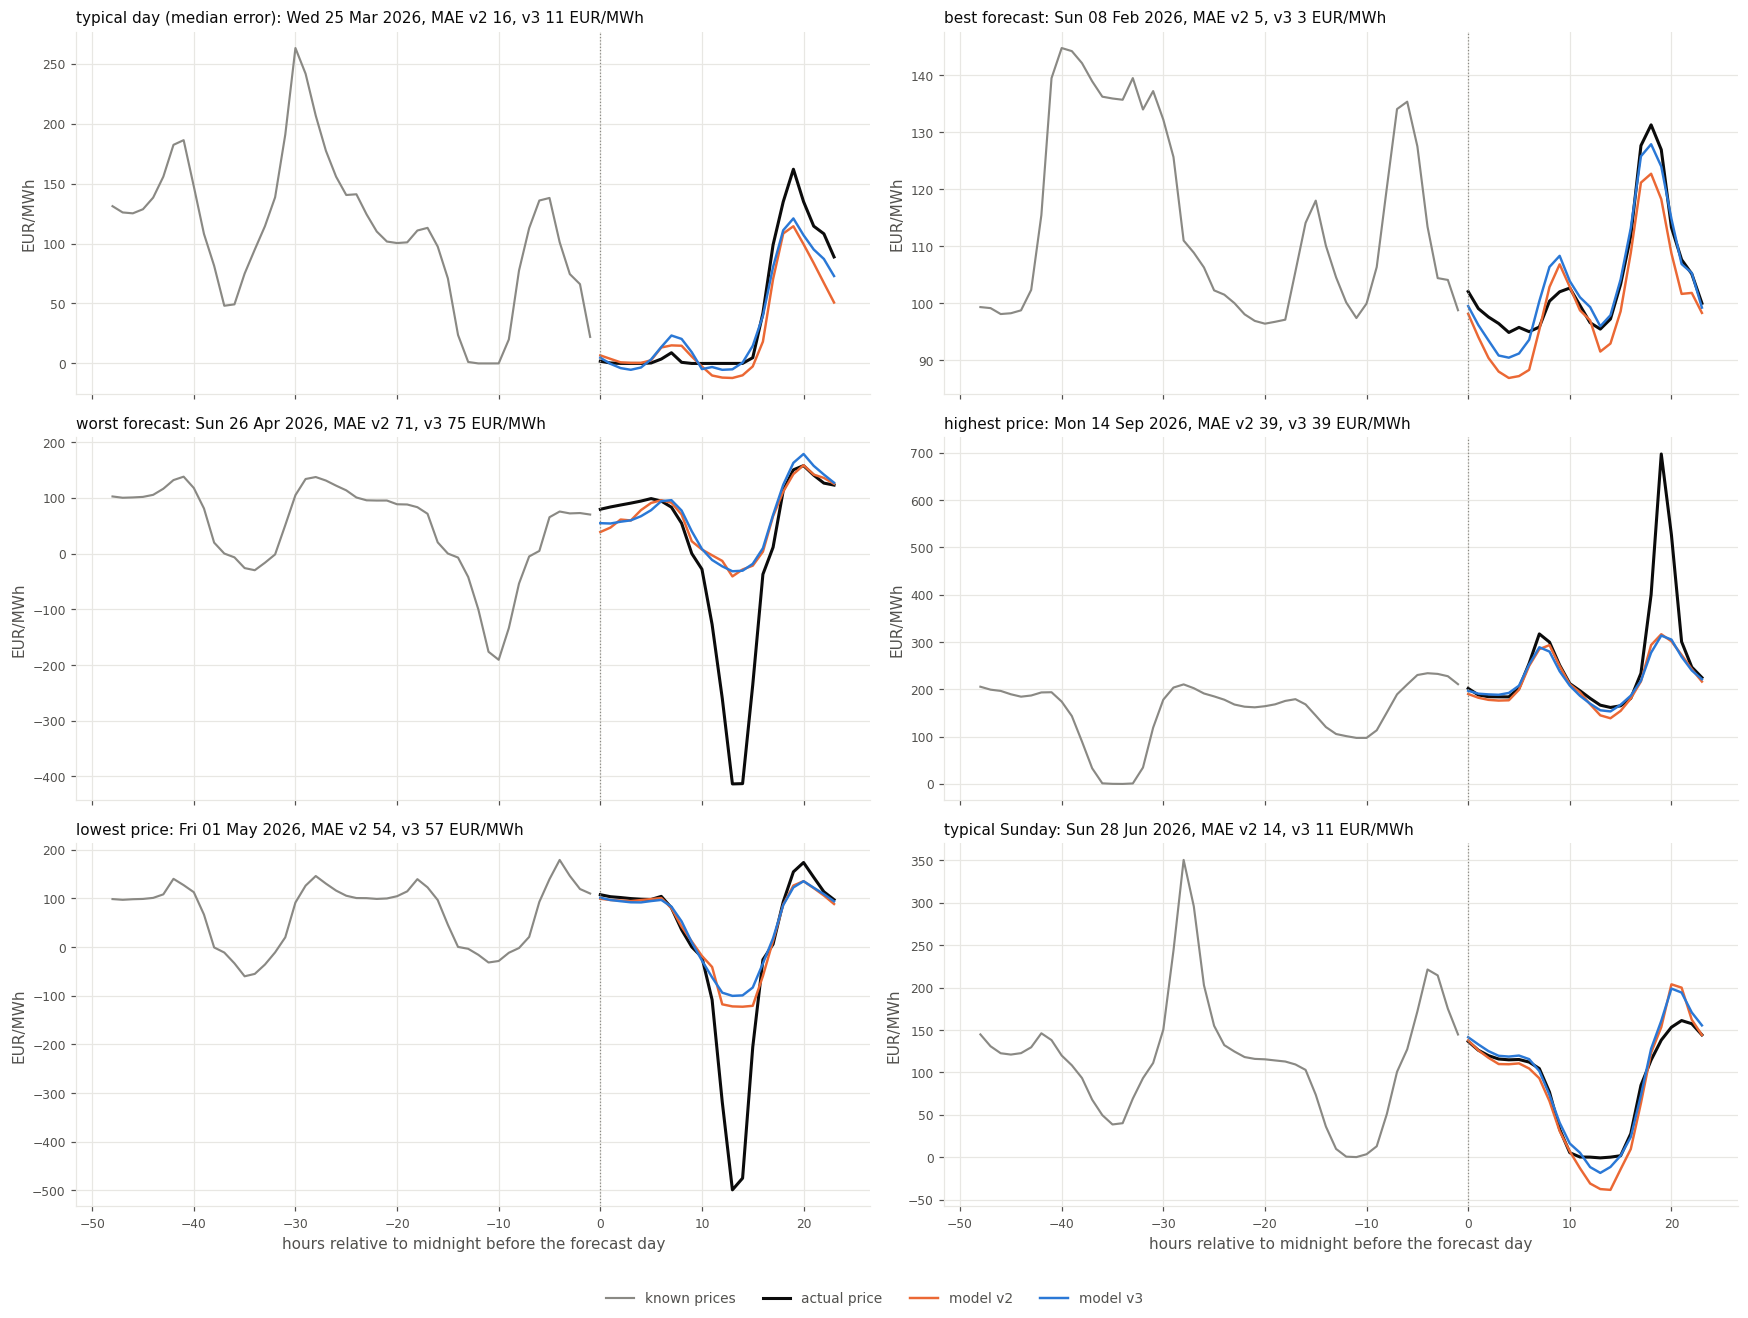

In [7]:
v3_mae = daily_mae["v3"]
sundays = np.flatnonzero(days.dayofweek == 6)
candidates = {
    "typical day (median error)": [np.argsort(v3_mae)[len(v3_mae) // 2]],
    "best forecast": np.argsort(v3_mae),
    "worst forecast": np.argsort(v3_mae)[::-1],
    "highest price": [np.argmax(actual.max(axis=1))],
    "lowest price": [np.argmin(actual.min(axis=1))],
    "typical Sunday": sundays[np.argsort(v3_mae[sundays])][len(sundays) // 2:],
}
picks = {}
for title, indices in candidates.items():
    picks[title] = next(int(i) for i in indices if i not in picks.values())

fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharex=True)
for ax, (title, i) in zip(axes.flat, picks.items()):
    day = days[i]
    known = spot[day - pd.Timedelta(days=2):day - pd.Timedelta(hours=1)]
    ax.plot((known.index - day) / pd.Timedelta(hours=1), known, color=CONTEXT_COLOR, linewidth=1.4,
            label="known prices")
    ax.plot(range(24), actual[i], color=TEXT_COLOR, linewidth=2, label="actual price")
    for name in MAIN:
        ax.plot(range(24), forecasts[name][i], color=color(name), linewidth=1.6, label=label(name))
    ax.axvline(0, color=CONTEXT_COLOR, linewidth=0.8, linestyle=":")
    style_axes(ax, f"{title}: {day:%a %d %b %Y}, MAE v2 {daily_mae['v2'][i]:.0f}, v3 {v3_mae[i]:.0f} EUR/MWh")
    ax.set_ylabel("EUR/MWh")
for ax in axes[-1]:
    ax.set_xlabel("hours relative to midnight before the forecast day")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, fontsize=9, labelcolor=MUTED_COLOR)
fig.tight_layout(rect=(0, 0.035, 1, 1))
plt.show()

## Summary

- Over the whole test period model v3 has an MAE of 13.5 EUR/MWh, model v2 16.9; the median daily MAE is 11.3 against 12.8, and model v3 beats the prices of the day before on 85 % of the days against 78 %.
- **Until April 2026 both are equally accurate** (11.9 against 11.8; model v3 is better on 43 % of these days). **The whole difference comes from May to October 2026** (17.0 against 28.0; model v3 is better on 88 % of these days), when the price rose from about 80 to 163 EUR/MWh: model v2 falls behind the level (a bias of −7.5 overall, −6.3 at prices up to 200), model v3 keeps it (−2.4 and −1.0).
- Model v3 is therefore not more accurate in a stable market, but robust to a moving price level, which a model in operation needs. Its three changes aim at exactly that: the fuel prices give the cause of the level, the LSTM carries it forward, the monthly refits bring in the newest days.
- By price level, model v3 is better from 50 to 200 EUR/MWh (150 to 200: 14.7 against 24.3), model v2 slightly at 0 to 50 (15.5 against 16.9). The extremes are hard for both: below 0 about 20, above 200 about 45, and both underestimate the prices above 200 EUR/MWh by about 34 on average.
- The hourly errors of both correlate with 0.84: on most days they make the same errors, from the same inputs.